# rhizodep in metafspm: root growth limited by resources

In metafspm, rhizodep's growth component specialises an architecture:

- **`RootArchitecture`**, ArchiSimple's root architecture without carbon, a package of its own
  (`openalea.archisimple`, with its tutorial): the apices' development (elongation from their diameter, growth durations,
  emergences, stops, deaths), the pipe model, segmentation and lateral primordia; its growth is the potential growth times
  the plant's satisfaction coefficient;
- **`RootGrowth(RootArchitecture)`**, rhizodep's: the same architecture with its growth limited by resources (hexose by
  default), and root hairs: each elongating apex draws on the hexose of its supply zone, each thickening segment on its
  own, and the costs are taken from the elements that supply them. It is the original component's model
  (`openalea.rhizodep.legacy`), with the reviewed fixes.

Both are `StructuralComponent`s: they build each plant's root system in metafspm's multiscale plant graph (MPG) and grow
it there, every root element (segment or apex) a SubOrgan.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.scene.scene import Scene
from openalea.rhizodep.growth import RootGrowth
from openalea.rhizodep.comparison.parameter_sets import WHEAT_SOISSON
from openalea.rhizodep.comparison.port_run import snapshot
from openalea.archisimple.drawing import draw_root_system, totals

## 1. A plant model, a planting table

A plant model names its **initiators** (the components that build each plant: here `RootGrowth`, which builds the
seedling) and its components. Here the hexose is given (a carbon model would compute it), so the model writes it before
each step.

In [2]:
class Roots:
    initiators = (RootGrowth,)

    def __init__(self, data_structure, time_step, C_hexose_root=1e-3):
        self.data_structure, self.C_hexose_root = data_structure, C_hexose_root
        self.growth = RootGrowth(data_structure=data_structure, time_step=time_step)
        self.components = [self.growth]

    def run(self):
        self.data_structure.set("C_hexose_root", np.full(self.data_structure.n_nodes(), self.C_hexose_root))
        self.growth()


def planting(model, scenarios):
    """One plant per scenario, side by side."""
    table = pd.DataFrame([dict(plant=f"plant {i}", model=model, x=0.2 * i, y=0., z=0., rotation=0., scenario=s)
                          for i, s in enumerate(scenarios)])
    table.attrs.update(xrange=0.2 * len(scenarios), yrange=0.2)
    return table

## 2. Parametrization by scenario

A plant's scenario sets the components' parameters over their defaults, as Wheat-BRIDGES' scenarios do (here the
`wheat_soisson` column of its scenario table). Numeric parameters are per plant: two plants of one population may differ.

In [3]:
thin = dict(WHEAT_SOISSON, D_ini=4e-4)
scene = Scene(planting(Roots, [{"parameters": WHEAT_SOISSON}, {"parameters": thin}]), time_step=3600)
scene.simulate(24 * 8)                                     # 8 days, hourly
ds = scene.populations[0].data_structure
print(f"{ds.n_nodes()} root elements in {len(ds.entity_ids('Plant'))} plants")
print("D_ini per plant:", scene.populations[0].instance.growth.D_ini)

619 root elements in 2 plants
D_ini per plant: [0.0007 0.0004]


The variables are arrays of the DataStructure, one value per element; coarser scales aggregate them. The MPG groups
the elements: an **Organ** per root axis (its `<` chain of segments), an **Axis** per first-order root with its laterals.
The seminal and nodal roots branch on the base segment, which stands for the seed. Elements are identified by their
MPG ids; their random draws are keyed by their **lineage key** (from their parent's key, their edge and rank), so a
plant's draws depend neither on the order the elements are visited nor on the other plants.

In [4]:
g = ds.mtg
plant_of = np.asarray(ds.entity_ids("Plant"))[ds.owner("Plant")]
length = ds.get("length")
for plant in ds.entity_ids("Plant"):
    axes = [a for a in g.components_at_scale(int(plant), g.scales.Axis) if not g.property("isanchor").get(a)]
    print(f"plant {plant}: {len(axes)} axes, {length[plant_of == plant].sum():.3f} m of roots")

plant 11: 55 axes, 0.847 m of roots
plant 12: 55 axes, 0.447 m of roots


## 3. The root systems

`snapshot` reads one plant's state in the legacy's form (the comparison tools' format) and `draw_root_system` draws it,
here coloured by radius.

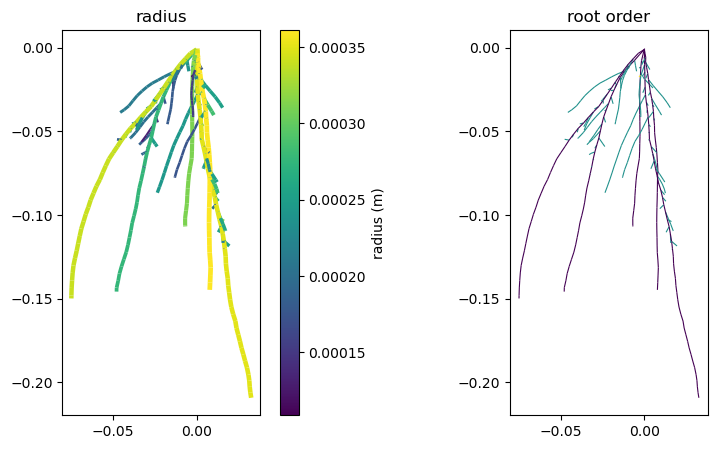

{'length': 1.4481198859980553,
 'struct_mass': 0.052796323927952464,
 'living_struct_mass': 0.05355472025005007,
 'vertices': 610,
 'apices': 326,
 'lateral_apices': 271}

In [5]:
one = Scene(planting(Roots, [{"parameters": WHEAT_SOISSON}]), time_step=3600)
one.simulate(24 * 10)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
lines = draw_root_system(axes[0], snapshot(one), color_by="radius")
fig.colorbar(lines, ax=axes[0], label="radius (m)")
draw_root_system(axes[1], snapshot(one), color_by="root_order", linewidth_by_radius=False)
axes[0].set_title("radius"); axes[1].set_title("root order")
plt.show()
totals(snapshot(one))

## 4. The original component and the reviewed fixes

Some behaviours of the original component were errors (devplan_metafspm.md §6, §25): the pipe model blind to its
children, the growth durations drawn twice, every seminal root drawn the same, the dead counted as living, ... The port
has the fixes only. It reproduced the original bit for bit first (the tag `port-exact` keeps that state, with the
original's behaviours as options); it is now validated statistically against that tag, over seeds. The original
(`openalea.rhizodep.legacy`, frozen) still runs on its own: the same model, other draws.

In [6]:
import contextlib, io
from openalea.rhizodep.comparison.legacy_run import legacy_run

with contextlib.redirect_stdout(io.StringIO()):                    # the original prints its tables' notes
    original = legacy_run(WHEAT_SOISSON, n_steps=24 * 10, record_every=24 * 10).steps[-1]
for label, record in (("original", original), ("port", snapshot(one))):
    t = totals(record)
    print(f"{label:9s} {t['length']:.3f} m, {t['struct_mass'] * 1e3:.1f} mg, {t['apices']} apices")

original  1.546 m, 52.2 mg, 318 apices
port      1.448 m, 52.8 mg, 326 apices


`example/comparison/compare_root_systems.py` draws the port against the original and compares their totals over
seeds; `profile_growth.py` and `profile_population.py` their costs.

## 5. Resources: a subclass

`RootGrowth.resources` lists the resources limiting growth, each a `Resource`: the declared variables of its
concentration, its supply zone, its costs. The **hooks** are the places where a resource acts: `elongated_length`,
`growth_demand`, `elongation_costs`, `thickening`, `root_hair_costs`, ... each a small array function. A subclass adds
a resource by declaring its variables and overriding the hooks it changes: Root_BRIDGES' carbon-nitrogen growth is
`openalea.rhizodep.growth_CN.RootGrowthCN` (about 250 lines against Root_BRIDGES' 2700; at the tag `port-exact`, bit for
bit Root_BRIDGES' results). An abridged version, the elongation co-limited by amino acids:

```python
@dataclass
class RootGrowthCN(RootGrowth):
    AA: float = input_variable(**doc('mol.g-1', 'Amino acids concentration'), by='model_nitrogen', initialize=0.,
                               scale=SubOrgan, state_variable_type='massic_concentration')
    ...                                                  # the amino acids' supply zone, demand, consumptions
    resources = (HEXOSE, AMINO_ACIDS)

    def elongated_length(self, selected, start_length, radius, time, zone):
        C, AA = zone["C_hexose_root"][selected], zone["AA"][selected]
        share = self._C_share_of_amino_acids(selected)
        limitation = (1 - share) * C / (C + Km_C) + share * AA / (AA + Km_AA)
        return start_length + self._parameter("EL", selected) * 2. * radius * time * limitation
```

## 6. Coupled: the other models' variables follow the structure

When segmentation creates elements, the other components' variables on the same DataStructure are shared between the
new elements and their parents by metafspm (`RootGrowth.repartition = "end_of_call"`), by the living structural mass:
concentrations keep their amounts, extensive variables are split, intensive ones copied. Here another model's
concentration and amount, conserved through 3 days of growth.

In [7]:
from dataclasses import dataclass
from openalea.metafspm.coupling.component import FunctionalComponent, state_variable
from openalea.metafspm.data_structure.configs import ScalesConfig

DOC = dict(unit="", unit_comment="", description="", min_value="", max_value="", value_comment="", references="", DOI="")


@dataclass
class Pools(FunctionalComponent):
    sugar: float = state_variable(**DOC, initialize=1e-3, scale=ScalesConfig.SubOrgan,
                                  state_variable_type="massic_concentration")
    stock: float = state_variable(**DOC, initialize=1., scale=ScalesConfig.SubOrgan, state_variable_type="extensive")


class RootsAndPools(Roots):
    def __init__(self, data_structure, time_step):
        super().__init__(data_structure, time_step)
        self.pools = Pools(data_structure=data_structure)
        self.components.append(self.pools)


coupled = Scene(planting(RootsAndPools, [{"parameters": WHEAT_SOISSON}]), time_step=3600)
ds = coupled.populations[0].data_structure
before = (np.sum(ds.get("sugar") * ds.get("living_struct_mass")), np.sum(ds.get("stock")), ds.n_nodes())
coupled.simulate(72)
after = (np.sum(ds.get("sugar") * ds.get("living_struct_mass")), np.sum(ds.get("stock")), ds.n_nodes())
print(f"elements {before[2]} -> {after[2]}; sugar amount {before[0]:.6g} -> {after[0]:.6g}; stock {before[1]:.6g} -> {after[1]:.6g}")

elements 56 -> 101; sugar amount 5.38783e-08 -> 5.38783e-08; stock 56 -> 56


## 7. A population in one MPG

A stand's plants are grown together: the planting table gives each its position and scenario, and one population
(one model instance, one DataStructure) holds them all, their elements in the same arrays. Each step is one call for
the whole stand, where the original component grows one plant per model, with loops over its MTG. Each plant is the
same as grown alone (`test/test_population.py`: bit for bit, each with its scenario, its draws keyed by lineage).

The plants of one population differ by their numeric parameters (stored per plant); a switch (a boolean option) is the
population's: plants with another switch make another population, of another model.

The stand grows 10 days: the wheat's laterals emerge a few days after their primordia form (their emergence delay, in thermal
time), so at 5 days they are still primordia, a fraction of a millimetre; at 10 days they make half the length.

In [8]:
import time
from openalea.metafspm.scene.population import planting_table

n_plants, days = 16, 10
scenarios = [{"parameters": dict(WHEAT_SOISSON, random_choice=1 + k)} for k in range(n_plants)]    # their own draws
stand = planting_table(xrange=0.4, yrange=0.4, sowing_density=n_plants / 0.16, row_spacing=0.1, plant_models=[Roots],
                       plant_scenarios=[scenarios[0]], per_plant_scenarios=scenarios, exact=True, seed=0)
start = time.perf_counter()
population = Scene(stand, time_step=3600)
population.simulate(24 * days)
port_seconds = time.perf_counter() - start
ds = population.populations[0].data_structure
print(f"{len(ds.entity_ids('Plant'))} plants, {ds.n_nodes()} root elements in one MPG: {port_seconds:.1f} s")

start = time.perf_counter()
with contextlib.redirect_stdout(io.StringIO()):                    # the original prints its tables' notes
    for scenario in scenarios:                                     # the original: one plant per model and run
        legacy_run(scenario["parameters"], n_steps=24 * days, record=False)
legacy_seconds = time.perf_counter() - start
print(f"the original, plant by plant: {legacy_seconds:.1f} s; the population {legacy_seconds / port_seconds:.1f} times faster")

Launching scene 'population' with 4 rows, 4 plant per rows, which represents 16 plants


16 plants, 10301 root elements in one MPG: 4.6 s


the original, plant by plant: 63.5 s; the population 13.9 times faster


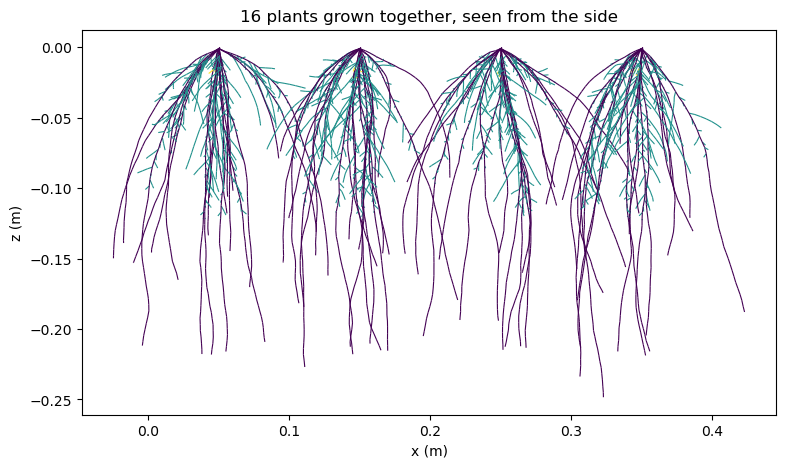

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
for plant in range(n_plants):                                       # each at its position in the row (x)
    draw_root_system(ax, snapshot(population, plant), color_by="root_order", linewidth_by_radius=False,
                     origin=(stand.x[plant], stand.y[plant], 0.), vmin=1, vmax=3)
ax.set_title(f"{n_plants} plants grown together, seen from the side")
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)")
plt.show()